In [12]:
import numpy as np, matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier

digit = load_digits()
X, y = digit.data, digit.target

K trop petit (K=1) : le modèle est très sensible au bruit, ce qui donne un risque de surapprentissage (variance élevée).
K trop grand : les frontières deviennent trop lisses et le modèle sous-apprend (biais élevé).

In [8]:
# ---- 1a) choix empirique de K sur un split train/test
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
ks = range(1, 31)
test_scores = [KNeighborsClassifier(k).fit(x_train, y_train).score(x_test, y_test) for k in ks]
best = ks[int(np.argmax(test_scores))]
print("1a) meilleur K sur test:", best, "score", max(test_scores))

1a) meilleur K sur test: 6 score 0.9955555555555555


In [9]:
# ---- 1b) protocole rigoureux : test mis de côté, CV 5-fold sur le train uniquement
cv = StratifiedKFold(5, shuffle=True, random_state=42)
cv_mean = [cross_val_score(KNeighborsClassifier(k), x_train, y_train, cv=cv).mean() for k in ks]
cv_std  = [cross_val_score(KNeighborsClassifier(k), x_train, y_train, cv=cv).std() for k in ks]
k_cv = ks[int(np.argmax(cv_mean))]
final = KNeighborsClassifier(k_cv).fit(x_train, y_train)
print("1b) meilleur K par CV:", k_cv, "CV acc", round(max(cv_mean),4))
print("    score test final (1 seule fois):", round(final.score(x_test, y_test),4))

1b) meilleur K par CV: 1 CV acc 0.9881
    score test final (1 seule fois): 0.9822


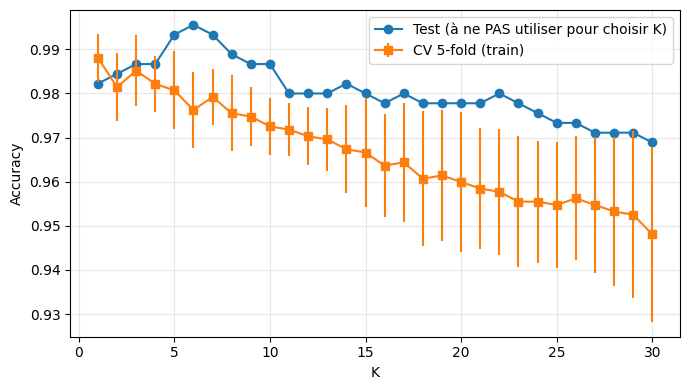

<Figure size 640x480 with 0 Axes>

In [14]:
plt.figure(figsize=(7,4))
plt.plot(ks, test_scores, 'o-', label="Test (à ne PAS utiliser pour choisir K)")
plt.errorbar(ks, cv_mean, yerr=cv_std, fmt='s-', label="CV 5-fold (train)")
plt.xlabel("K");
plt.ylabel("Accuracy");
plt.legend();
plt.grid(alpha=.3)
plt.tight_layout();
plt.show()
plt.savefig("q1_k.png", dpi=120)


Problème : fuite de données (data leakage) et surapprentissage sur le jeu de test. Si on choisit K en maximisant le score sur x_test, le jeu de test a participé à la sélection du modèle. Le score obtenu est alors optimiste : il ne mesure plus la capacité de généralisation. Le test doit servir une seule fois, à la toute fin.